Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0641 - val_loss: 0.0359
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0301 - val_loss: 0.0252
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0237 - val_loss: 0.0216
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0206 - val_loss: 0.0189
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0184 - val_loss: 0.0170


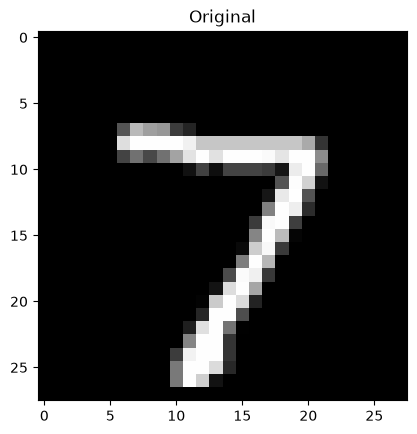

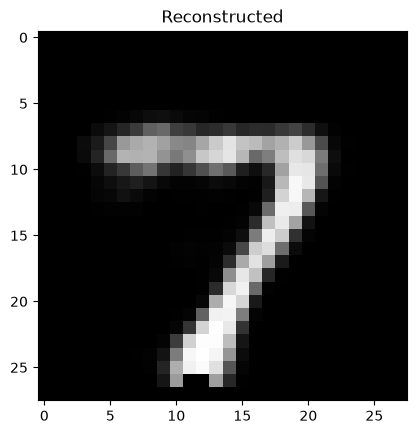

In [2]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

(train_images,_),(test_images,_) = tf.keras.datasets.mnist.load_data()
train_images = train_images.reshape(-1,784)/255.0
test_images = test_images.reshape(-1,784)/255.0

input_image = layers.Input(shape=(784,))
encoded = layers.Dense(128,activation='relu')(input_image)
encoded = layers.Dense(64,activation='relu')(encoded)
encoded = layers.Dense(32,activation='relu')(encoded)
decoded = layers.Dense(64,activation='relu')(encoded)
decoded = layers.Dense(128,activation='relu')(decoded)
output_image = layers.Dense(784,activation='sigmoid')(decoded)

autoencoder = models.Model(input_image,output_image)
autoencoder.compile(optimizer='adam',loss='mse')
autoencoder.fit(train_images,train_images,epochs=5,batch_size=256,
                validation_data=(test_images,test_images))

reconstructed_images = autoencoder.predict(test_images,verbose=0)


plt.imshow(test_images[0].reshape(28,28),cmap='gray')
plt.title('Original')
plt.show()
plt.imshow(reconstructed_images[0].reshape(28,28),cmap='gray')
plt.title('Reconstructed')
plt.show()
